# 04 · Results

Aggregate per-model metrics into the comparison table and a performance figure.

In [1]:
import os
from pathlib import Path
# Run from the repo root so the package's relative paths (data/, outputs/) resolve.
if Path.cwd().name == 'notebooks':
    os.chdir('..')
print('cwd:', Path.cwd())

cwd: /home/emre/Projeler/MalariaCellsThesis


## Comparison table

In [2]:
import json
import pandas as pd
from malaria_vit.config import MODELS, OUTPUTS_DIR
LABELS = {'deit_s': 'DeiT-S', 'swin_t': 'Swin-T', 'vit_b16': 'ViT-B/16'}
rows = []
for key in MODELS:
    m = json.loads((OUTPUTS_DIR / key / 'metrics.json').read_text()); e = m['efficiency']
    rows.append({'model': LABELS[key], 'accuracy': m['accuracy'], 'f1': m['f1'],
                 'roc_auc': m['roc_auc'], 'params_M': e['params_millions'],
                 'latency_ms': e['latency_ms'], 'gflops': e['gflops']})
table = pd.DataFrame(rows)
table.round(4)

,model,accuracy,f1,roc_auc,params_M,latency_ms,gflops
0,DeiT-S,0.9664,0.9657,0.9939,21.6664,7.3721,4.2503
1,Swin-T,0.9713,0.9713,0.9955,27.5209,14.0723,4.5084
2,ViT-B/16,0.9735,0.9731,0.9957,85.8002,19.2621,16.8666


## Performance figure

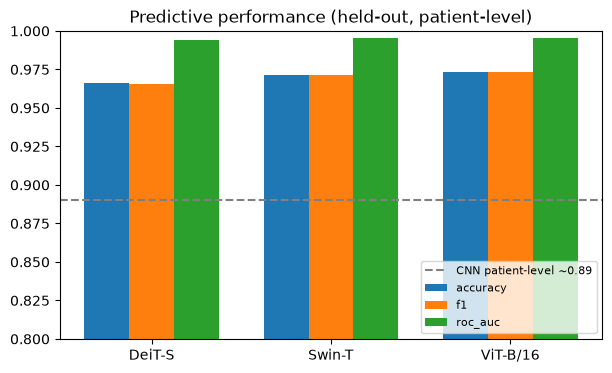

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(7, 4))
w, x = 0.25, range(len(table))
for i, mt in enumerate(['accuracy', 'f1', 'roc_auc']):
    ax.bar([xi + i * w for xi in x], table[mt], width=w, label=mt)
ax.axhline(0.89, ls='--', color='grey', label='CNN patient-level ~0.89')
ax.set_xticks([xi + w for xi in x]); ax.set_xticklabels(table['model'])
ax.set_ylim(0.8, 1.0); ax.set_title('Predictive performance (held-out, patient-level)')
ax.legend(fontsize=8, loc='lower right'); plt.show()

See `docs/results.md` for the written record and `docs/figures/` for the saved figures (performance, accuracy-vs-params, accuracy-vs-latency, confusion matrices).